# Pipeline 2: Modelo de Predicción y Visualización
**Challenge 1 (Individual) – Machine Learning – UPCH**
**Caso Tipo C: Sueño en los Recién Nacidos**

**Tarea de ML:** regresión supervisada. Predecir la **duración del ciclo de sueño (min)** a partir de la **edad del bebé (meses)**.

Pipeline: Datos sintéticos → Exploración → Separar train/test → Entrenar modelos → Evaluar → Gráfico interpretativo → Conclusiones.

> **Importante:** los datos son **sintéticos**, generados a partir de lo que reporta la infografía (ciclo de ~40 min a los 3 meses que aumenta ~10 min hasta los 12 meses; 162 bebés con seguimiento a los 3, 6 y 12 meses). No son datos reales del estudio.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

rng = np.random.default_rng(42)

## 1. Datos sintéticos a partir del caso
Cada bebé se mide a los **3, 6 y 12 meses**. El ciclo de sueño sigue la tendencia reportada (+10 min entre los 3 y los 12 meses), más una diferencia propia de cada bebé y ruido de medición.

Las variables `lactancia` y `actividad_motora` se incluyen como covariables observables (aparecen en la infografía) pero **se generan sin efecto** sobre el ciclo, porque la infografía indica que la causalidad de la lactancia **no se reporta**.

In [10]:
N_BEBES = 162
EDADES = [3, 6, 12]  # meses

filas = []
for bebe in range(N_BEBES):
    efecto_bebe = rng.normal(0, 2.0)               # diferencia individual (min)
    lactancia = rng.integers(0, 2)                 # 1 = lactancia materna (sin efecto simulado)
    for edad in EDADES:
        ciclo = 40 + (10 / 9) * (edad - 3) + efecto_bebe + rng.normal(0, 2.5)
        actividad = max(0, rng.normal(50 + 2 * edad, 10))   # índice arbitrario, sin efecto simulado
        filas.append({"bebe_id": bebe, "edad_meses": edad, "lactancia": lactancia,
                      "actividad_motora": round(actividad, 1), "ciclo_min": round(ciclo, 2)})

df = pd.DataFrame(filas)
print(df.shape)
df.head()

(486, 5)


,bebe_id,edad_meses,lactancia,actividad_motora,ciclo_min
0,0,3,1,65.4,42.49
1,0,6,1,49.0,39.07
2,0,12,1,70.8,50.93
3,1,3,0,64.8,37.83
4,1,6,0,62.7,45.24


In [11]:
print(df.groupby("edad_meses")["ciclo_min"].agg(["mean", "std", "count"]).round(2))

             mean   std  count
edad_meses                    
3           39.60  2.98    162
6           43.29  3.00    162
12          49.82  3.04    162


## 2. Separar entrenamiento y prueba
Para evitar fugas de información, separamos **por bebé**: un mismo bebé no puede estar a la vez en entrenamiento y prueba.

In [12]:
ids = df["bebe_id"].unique()
ids_train, ids_test = train_test_split(ids, test_size=0.25, random_state=42)
train = df[df["bebe_id"].isin(ids_train)]
test = df[df["bebe_id"].isin(ids_test)]
print("Bebés train/test:", len(ids_train), len(ids_test), "| filas:", len(train), len(test))

X_cols_simple = ["edad_meses"]
X_cols_multiple = ["edad_meses", "lactancia", "actividad_motora"]
y_col = "ciclo_min"

Bebés train/test: 121 41 | filas: 363 123


## 3. Modelo de regresión elegido y sustento
**Modelo principal: Regresión lineal simple**  `ciclo = β₀ + β₁ · edad`

**Por qué lo elegimos:**
- La variable objetivo es **continua** (minutos), por lo que corresponde una tarea de **regresión**.
- La infografía reporta un aumento aproximado de ~10 min en 9 meses: una relación **aproximadamente lineal** y fácil de interpretar.
- `β₁` tiene lectura directa: *minutos que aumenta el ciclo por cada mes de edad*.
- Es un modelo simple, transparente y adecuado cuando hay pocas variables observables.

Lo comparamos con (a) un **polinomio de grado 2** (¿hay curvatura?) y (b) una **regresión múltiple** con lactancia y actividad motora (¿aportan algo?).

In [13]:
modelos = {
    "Lineal simple (edad)": (make_pipeline(LinearRegression()), X_cols_simple),
    "Polinomial grado 2 (edad)": (make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()), X_cols_simple),
    "Múltiple (edad + lactancia + actividad)": (make_pipeline(LinearRegression()), X_cols_multiple),
}

filas = []
for nombre, (modelo, cols) in modelos.items():
    modelo.fit(train[cols], train[y_col])
    pred = modelo.predict(test[cols])
    filas.append({
        "Modelo": nombre,
        "R² (test)": r2_score(test[y_col], pred),
        "MAE (min)": mean_absolute_error(test[y_col], pred),
        "RMSE (min)": mean_squared_error(test[y_col], pred) ** 0.5,
    })

metricas = pd.DataFrame(filas).set_index("Modelo").round(3)
metricas

,R² (test),MAE (min),RMSE (min)
Modelo,,,
Lineal simple (edad),0.707,2.344,2.833
Polinomial grado 2 (edad),0.707,2.354,2.832
Múltiple (edad + lactancia + actividad),0.709,2.335,2.822


In [14]:
lineal = modelos["Lineal simple (edad)"][0]
b1 = lineal[-1].coef_[0]
b0 = lineal[-1].intercept_
print(f"Ecuación: ciclo = {b0:.2f} + {b1:.3f} * edad_meses")
print(f"Interpretación: por cada mes de edad, el ciclo aumenta ~{b1:.2f} min")
print(f"Entre 3 y 12 meses: ~{b1 * 9:.1f} min (la infografía reporta ~10 min)")

multiple = modelos["Múltiple (edad + lactancia + actividad)"][0]
coefs = dict(zip(X_cols_multiple, multiple[-1].coef_.round(3)))
print("Coeficientes del modelo múltiple:", coefs)
print("-> lactancia y actividad motora casi no aportan (simulados sin efecto). "
      "En datos reales, esto NO implicaría ausencia de causalidad.")

Ecuación: ciclo = 36.27 + 1.101 * edad_meses
Interpretación: por cada mes de edad, el ciclo aumenta ~1.10 min
Entre 3 y 12 meses: ~9.9 min (la infografía reporta ~10 min)
Coeficientes del modelo múltiple: {'edad_meses': np.float64(1.059), 'lactancia': np.float64(-0.406), 'actividad_motora': np.float64(0.021)}
-> lactancia y actividad motora casi no aportan (simulados sin efecto). En datos reales, esto NO implicaría ausencia de causalidad.


## 4. Gráfico interpretativo
- **Izquierda:** datos de prueba, promedio por edad y recta de regresión con banda de ±1,96 σ de los residuos.
- **Derecha:** valores reales vs. predichos; cuanto más cerca de la diagonal, mejor el modelo.

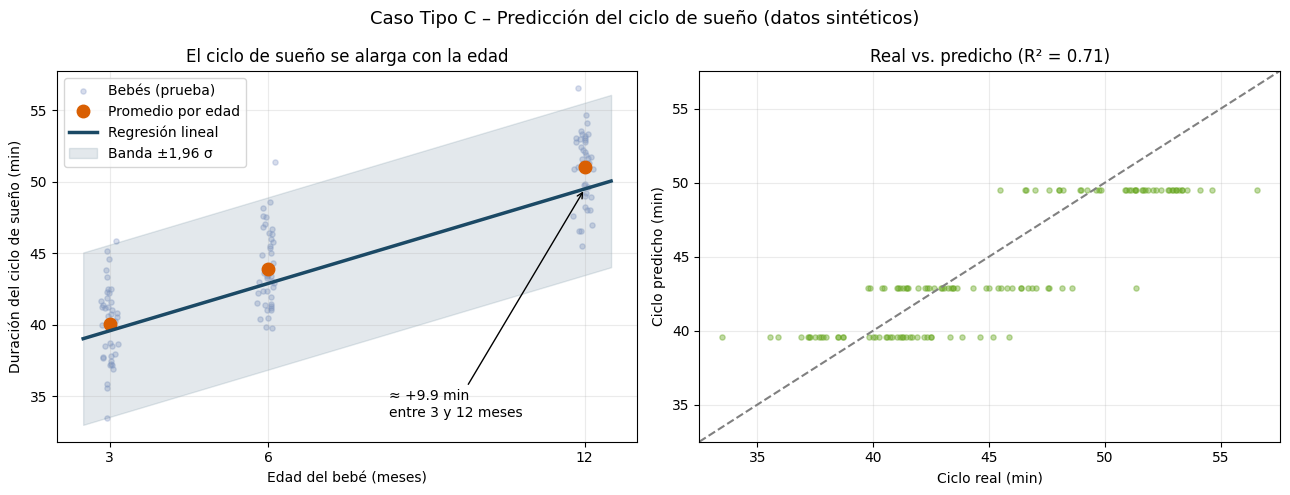

In [15]:
residuos = train[y_col] - lineal.predict(train[X_cols_simple])
sigma = residuos.std()

grid = pd.DataFrame({"edad_meses": np.linspace(2.5, 12.5, 100)})
pred_grid = lineal.predict(grid)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Panel izquierdo
jitter = rng.normal(0, 0.08, len(test))
ax[0].scatter(test["edad_meses"] + jitter, test[y_col], s=14, alpha=0.35, color="#8da0cb", label="Bebés (prueba)")
medias = test.groupby("edad_meses")[y_col].mean()
ax[0].plot(medias.index, medias.values, "o", color="#d95f02", markersize=9, label="Promedio por edad")
ax[0].plot(grid["edad_meses"], pred_grid, color="#1b4965", linewidth=2.5, label="Regresión lineal")
ax[0].fill_between(grid["edad_meses"], pred_grid - 1.96 * sigma, pred_grid + 1.96 * sigma,
                   color="#1b4965", alpha=0.12, label="Banda ±1,96 σ")
p3, p12 = lineal.predict(pd.DataFrame({"edad_meses": [3, 12]}))
ax[0].annotate(f"≈ +{p12 - p3:.1f} min\nentre 3 y 12 meses", xy=(12, p12), xytext=(8.3, p3 - 6),
               arrowprops=dict(arrowstyle="->"), fontsize=10)
ax[0].set_xticks(EDADES)
ax[0].set_xlabel("Edad del bebé (meses)")
ax[0].set_ylabel("Duración del ciclo de sueño (min)")
ax[0].set_title("El ciclo de sueño se alarga con la edad")
ax[0].legend(loc="upper left")
ax[0].grid(alpha=0.25)

# Panel derecho
pred_test = lineal.predict(test[X_cols_simple])
lim = [min(test[y_col].min(), pred_test.min()) - 1, max(test[y_col].max(), pred_test.max()) + 1]
ax[1].scatter(test[y_col], pred_test, s=14, alpha=0.4, color="#66a61e")
ax[1].plot(lim, lim, "--", color="gray")
ax[1].set_xlim(lim); ax[1].set_ylim(lim)
r2 = r2_score(test[y_col], pred_test)
ax[1].set_title(f"Real vs. predicho (R² = {r2:.2f})")
ax[1].set_xlabel("Ciclo real (min)")
ax[1].set_ylabel("Ciclo predicho (min)")
ax[1].grid(alpha=0.25)

plt.suptitle("Caso Tipo C – Predicción del ciclo de sueño (datos sintéticos)", fontsize=13)
plt.tight_layout()
plt.savefig("grafico_regresion.jpeg", dpi=150, format="jpeg")
plt.show()

In [16]:
for edad in [1, 3, 6, 9, 12]:
    p = lineal.predict(pd.DataFrame({"edad_meses": [edad]}))[0]
    print(f"Edad {edad:>2} meses -> ciclo esperado ≈ {p:.1f} min (rango ±{1.96 * sigma:.1f})")
print("\nNota: la edad de 1 mes queda fuera del rango entrenado (3-12 meses): es una extrapolación poco confiable.")

Edad  1 meses -> ciclo esperado ≈ 37.4 min (rango ±6.0)
Edad  3 meses -> ciclo esperado ≈ 39.6 min (rango ±6.0)
Edad  6 meses -> ciclo esperado ≈ 42.9 min (rango ±6.0)
Edad  9 meses -> ciclo esperado ≈ 46.2 min (rango ±6.0)
Edad 12 meses -> ciclo esperado ≈ 49.5 min (rango ±6.0)

Nota: la edad de 1 mes queda fuera del rango entrenado (3-12 meses): es una extrapolación poco confiable.


## 5. Conclusiones
1. Se eligió una **regresión lineal simple** porque la variable objetivo es continua y la infografía reporta un aumento aproximadamente lineal del ciclo con la edad.
2. El modelo captura la tendencia (≈ +1,1 min por mes) y su pendiente es interpretable.
3. El polinomio de grado 2 y la regresión múltiple **no mejoran** de forma relevante: en estos datos sintéticos no hay curvatura ni efecto de las covariables (por construcción).
4. **Limitaciones:** datos sintéticos; una sola relación; no se debe extrapolar fuera de 3–12 meses; la infografía no reporta causalidad ni efectos a largo plazo.
5. **Siguientes pasos:** usar actigrafía real (si se dispone), probar clustering de patrones de sueño y validar con especialistas en pediatría.